# NIST20 mbfs vs SMARTS-prepass — h4 peak-coverage comparison

Compare two NIST20 `d3` fragmentation DAG datasets:

| Config | Path | Mechanism |
|---|---|---|
| **prepass** | `nist20_ma_mi_d3_h4_isoFalse_smpTrue` | `smarts_prepass=True` (10 curated rules), single-bond BFS |
| **mbfs** | `nist20_ma_mi_d3_h4_isoFalse_smpFalse_mbfs` | `multi_cut_bfs=True`, ring-aware multi-bond-cut BFS, no SMARTS rules |

Question: at `h4` (up to 4 H-shifts, 0.01 Da tolerance), **which molecules does mbfs still
explain better than the curated SMARTS prepass** (higher intensity-weighted `wrecall_0.01_h4`)?
These are candidates for new SMARTS rules — mbfs finds them structurally via brute-force
ring-opening search, but no existing SMARTS rule captures the same rearrangement.

CMF (charge migration fragmentation) status is not a column in the stats dataframes — it is
derived per-spectrum from `prec_type` (see `PREC_TYPE_TO_CMF_MASS_DIFF` in
`src/fragnnet/utils/formula_utils.py`).

In [1]:
import io
import json
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FRAG_DP = Path("../../data/frag")
PROC_DP = Path("../../data/proc/nist20")

CONFIGS = {
    "prepass": FRAG_DP / "nist20_ma_mi_d3_h4_isoFalse_smpTrue",
    "mbfs": FRAG_DP / "nist20_ma_mi_d3_h4_isoFalse_smpFalse_mbfs",
}

DF_NAMES = ["spec_stats_df", "mol_stats_df", "m_spec_stats_df", "m_mol_stats_df"]

TOL = "0.01"
H = 4
WCOL = f"wrecall_{TOL}_h{H}"
RCOL = f"recall_{TOL}_h{H}"

# Direct-charge adducts: only delta_h=0 is a real CMF peak (proton/electron-only carrier).
# All other adducts in PREC_TYPE_TO_CMF_MASS_DIFF use full charge-migration H-shift range.
DIRECT_CHARGE_PREC_TYPES = {"[M+H]+", "[M-H]-"}
CMF_PREC_TYPES = {
    "[M+H]+", "[M+Na]+", "[M+H+2i]+", "[M+K]+", "[M+NH4]+", "[M-H2O+H]+",
    "[M-2H2O+H]+", "[M+H-NH3]+",
    "[M-H]-", "[M-H-CO2]-", "[M+Cl]-", "[M-H-H2O]-", "[M-H+2i]-",
    "[M+CH3COOH-H]-", "[M+CH3COO]-", "[M+HCOOH-H]-",
} - DIRECT_CHARGE_PREC_TYPES

In [2]:
def load_dfs(path: Path) -> dict[str, pd.DataFrame]:
    """Load all stats pkl files from a directory or a .tar archive."""
    dfs = {}
    if path.suffix == ".tar":
        with tarfile.open(path) as tf:
            members = {Path(m.name).name: m for m in tf.getmembers() if m.name.endswith(".pkl")}
            for name in DF_NAMES:
                fname = f"{name}.pkl"
                if fname in members:
                    f = tf.extractfile(members[fname])
                    dfs[name] = pd.read_pickle(io.BytesIO(f.read()))
        with tarfile.open(path) as tf:
            for m in tf.getmembers():
                if m.name.endswith("global_stats.json"):
                    f = tf.extractfile(m)
                    dfs["global_stats"] = json.load(f)
    else:
        for name in DF_NAMES:
            pkl_path = path / f"{name}.pkl"
            if pkl_path.exists():
                dfs[name] = pd.read_pickle(pkl_path)
        gs_path = path / "global_stats.json"
        if gs_path.exists():
            dfs["global_stats"] = json.loads(gs_path.read_text())
    return dfs


def _downcast_dfs(dfs: dict) -> dict:
    """Downcast float64 columns to float32 to halve memory usage."""
    for k, v in dfs.items():
        if isinstance(v, pd.DataFrame):
            f64_cols = v.select_dtypes(include="float64").columns
            dfs[k] = v.astype({c: "float32" for c in f64_cols})
    return dfs


all_dfs = {name: _downcast_dfs(load_dfs(path)) for name, path in CONFIGS.items()}
for name, dfs in all_dfs.items():
    print(name, {k: (v.shape if isinstance(v, pd.DataFrame) else type(v)) for k, v in dfs.items()})

prepass {'spec_stats_df': (490566, 177), 'mol_stats_df': (25969, 176), 'm_spec_stats_df': (77960, 177), 'm_mol_stats_df': (25969, 176), 'global_stats': <class 'dict'>}
mbfs {'spec_stats_df': (490566, 177), 'mol_stats_df': (25969, 176), 'm_spec_stats_df': (77960, 177), 'm_mol_stats_df': (25969, 176), 'global_stats': <class 'dict'>}


## Global stats summary

In [3]:
GS_KEYS = [
    "total_num_failures",
    "total_num_formulae",
    "dag_num_nodes/mean",
    "dag_num_nodes/50%",
    "dag_num_edges/mean",
    "dag_num_edges/50%",
    "num_formulae/mean",
    "num_formulae/50%",
    "formula_redundancy/mean",
    "formula_redundancy/50%",
    f"spec/recall_{TOL}_h{H}/mean",
    f"spec/wrecall_{TOL}_h{H}/mean",
    f"spec/wrecall_{TOL}_h{H}/50%",
    f"spec/prec_{TOL}_h{H}/mean",
]

rows = []
for cfg, dfs in all_dfs.items():
    gs = dfs.get("global_stats", {})
    row = {"config": cfg}
    for k in GS_KEYS:
        row[k] = gs.get(k, float("nan"))
    rows.append(row)

gs_df = pd.DataFrame(rows).set_index("config").T
gs_df

config,prepass,mbfs
total_num_failures,0,0
total_num_formulae,865459,987929
dag_num_nodes/mean,807.4010165967114,2411.1780584543108
dag_num_nodes/50%,319.0,490.0
dag_num_edges/mean,4593.935461511803,18433.88432361662
dag_num_edges/50%,1330.0,3118.0
num_formulae/mean,896.3494166121144,1105.3201894566598
num_formulae/50%,590.0,660.0
formula_redundancy/mean,4.701362440571861,10.005618899372852
formula_redundancy/50%,3.635294117647059,4.804347826086956


## Mol-level: which molecules have more peaks explained at h4?

Primary metric: `wrecall_0.01_h4` (intensity-weighted peak coverage) from `m_mol_stats_df`,
delta = mbfs − prepass, one row per `mol_id`.

In [4]:
base_mol = all_dfs["prepass"]["m_mol_stats_df"].set_index("mol_id")[[RCOL, WCOL]]
mbfs_mol = all_dfs["mbfs"]["m_mol_stats_df"].set_index("mol_id")[[RCOL, WCOL]]

common_mols = base_mol.index.intersection(mbfs_mol.index)
print(f"Molecules in common: {len(common_mols):,} (prepass={len(base_mol):,}, mbfs={len(mbfs_mol):,})")

mol_cmp = pd.DataFrame({
    f"{WCOL}_prepass": base_mol.loc[common_mols, WCOL],
    f"{WCOL}_mbfs": mbfs_mol.loc[common_mols, WCOL],
    f"{RCOL}_prepass": base_mol.loc[common_mols, RCOL],
    f"{RCOL}_mbfs": mbfs_mol.loc[common_mols, RCOL],
})
mol_cmp["wrecall_h4_delta"] = mol_cmp[f"{WCOL}_mbfs"] - mol_cmp[f"{WCOL}_prepass"]
mol_cmp["recall_h4_delta"] = mol_cmp[f"{RCOL}_mbfs"] - mol_cmp[f"{RCOL}_prepass"]

n_improved = (mol_cmp["wrecall_h4_delta"] > 1e-6).sum()
n_worse = (mol_cmp["wrecall_h4_delta"] < -1e-6).sum()
n_same = len(mol_cmp) - n_improved - n_worse
print(f"\nMolecules with MORE peaks explained under mbfs (h4): {n_improved:,} ({n_improved/len(mol_cmp):.1%})")
print(f"Molecules with FEWER peaks explained under mbfs (h4): {n_worse:,} ({n_worse/len(mol_cmp):.1%})")
print(f"Molecules unchanged: {n_same:,} ({n_same/len(mol_cmp):.1%})")
print(f"\nMean delta: {mol_cmp['wrecall_h4_delta'].mean():.4f}  Median delta: {mol_cmp['wrecall_h4_delta'].median():.4f}")
mol_cmp.describe()

Molecules in common: 25,969 (prepass=25,969, mbfs=25,969)

Molecules with MORE peaks explained under mbfs (h4): 9,080 (35.0%)
Molecules with FEWER peaks explained under mbfs (h4): 2,130 (8.2%)
Molecules unchanged: 14,759 (56.8%)

Mean delta: 0.0206  Median delta: 0.0000


,wrecall_0.01_h4_prepass,wrecall_0.01_h4_mbfs,recall_0.01_h4_prepass,recall_0.01_h4_mbfs,wrecall_h4_delta,recall_h4_delta
count,25969.000000,25969.000000,25969.000000,25969.000000,25969.000000,25969.000000
mean,0.922829,0.943407,0.795208,0.827599,0.020578,0.032392
std,0.097226,0.081814,0.142518,0.135165,0.058459,0.071919
min,0.000000,0.000000,0.000000,0.000000,-0.619540,-0.538043
25%,0.897969,0.930804,0.719212,0.759982,0.000000,0.000000
50%,0.956806,0.971598,0.823699,0.860688,0.000000,0.000000
75%,0.985940,0.990635,0.902106,0.928571,0.012488,0.043352
max,1.000000,1.000000,1.000000,1.000000,0.759838,0.725076


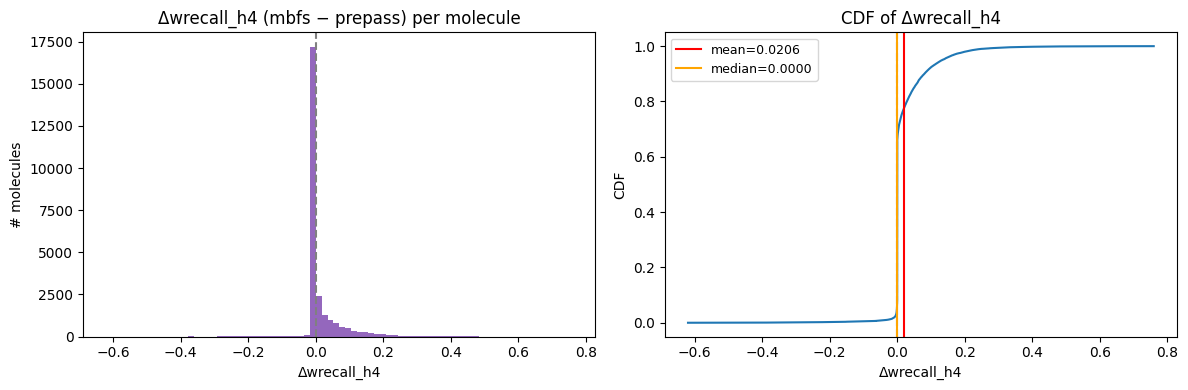

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(mol_cmp["wrecall_h4_delta"], bins=80, color="tab:purple")
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set_title("Δwrecall_h4 (mbfs − prepass) per molecule")
axes[0].set_xlabel("Δwrecall_h4")
axes[0].set_ylabel("# molecules")

vals = mol_cmp["wrecall_h4_delta"].sort_values()
cdf = np.arange(1, len(vals) + 1) / len(vals)
axes[1].plot(vals, cdf)
axes[1].axvline(0, color="gray", linestyle="--")
axes[1].axvline(vals.mean(), color="red", label=f"mean={vals.mean():.4f}")
axes[1].axvline(vals.median(), color="orange", label=f"median={vals.median():.4f}")
axes[1].set_title("CDF of Δwrecall_h4")
axes[1].set_xlabel("Δwrecall_h4")
axes[1].set_ylabel("CDF")
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

In [6]:
# Attach SMILES/formula for readability
mol_meta = pd.read_pickle(PROC_DP / "mol_df.pkl")[["mol_id", "smiles", "formula", "mw"]].set_index("mol_id")

top_improved = (
    mol_cmp.join(mol_meta, how="left")
    .sort_values("wrecall_h4_delta", ascending=False)
    .head(30)
)
top_improved[["smiles", "formula", "mw", f"{WCOL}_prepass", f"{WCOL}_mbfs", "wrecall_h4_delta"]]

,smiles,formula,mw,wrecall_0.01_h4_prepass,wrecall_0.01_h4_mbfs,wrecall_h4_delta
mol_id,,,,,,
31493,O=C1CC2OCC=C3CN4CCC56c7ccccc7N1C5C2C3CC46,C21H22N2O2,334.419,0.157249,0.917087,0.759838
34119,Oc1c2ccccc2c2c3c(cccc13)N=N2,C14H8N2O,220.231,0.243274,0.994121,0.750847
15421,CN1CCC23CCCCC2C1Cc1ccc(O)cc13,C17H23NO,257.377,0.252791,0.986384,0.733593
34342,Oc1ccc2c(c1)C13CCCCC1C(C2)NCC3,C16H21NO,243.350,0.282554,0.994586,0.712032
20146,COc1ccc2c(c1)C13CCCCC1C(C2)N(C)CC3,C18H25NO,271.404,0.289731,0.987304,0.697574
6844,CC12Cc3nonc3CC1CCC1C2CCC2(C)C1CC(O)C2(C)O,C20H30N2O3,346.471,0.272469,0.919785,0.647316
18918,COc1cc2c(cc1OC)C13CCN4CC5=CCOC6CC(=O)N2C1C6C5CC43,C23H26N2O4,394.471,0.232341,0.875325,0.642984
1412,C=CCN1CCC23CCCCC2C1Cc1ccc(O)cc13,C19H25NO,283.415,0.390682,0.993672,0.602989
14540,CCOc1ccc2nc3cc([N+](=O)[O-])ccc3c(N)c2c1,C15H13N3O3,283.287,0.365401,0.958778,0.593377


## CMF breakdown (spec-level)

CMF status is a per-spectrum property of `prec_type`, not per-molecule (one molecule can be
measured under several adducts). Join `spec_stats_df` with `prec_type` from `spec_df.pkl` and
compare the same h4 delta, grouped by adduct class:

- **direct-charge**: `[M+H]+` / `[M-H]-` — only `delta_h=0` is a real CMF peak
- **cmf**: other adducts in `PREC_TYPE_TO_CMF_MASS_DIFF` — full charge-migration H-shift range applies
- **other**: adducts not covered by CMF logic at all

In [7]:
spec_meta = pd.read_pickle(PROC_DP / "spec_df.pkl")[["spec_id", "mol_id", "prec_type"]].copy()
spec_meta["spec_id"] = spec_meta["spec_id"].astype(str)


def classify_adduct(prec_type: str) -> str:
    if prec_type in DIRECT_CHARGE_PREC_TYPES:
        return "direct_charge"
    if prec_type in CMF_PREC_TYPES:
        return "cmf"
    return "other"


spec_meta["adduct_class"] = spec_meta["prec_type"].apply(classify_adduct)
print(spec_meta["adduct_class"].value_counts())

adduct_class
direct_charge    537510
other            457636
cmf              152926
Name: count, dtype: int64


In [8]:
base_spec = all_dfs["prepass"]["spec_stats_df"][["spec_id", WCOL]].copy()
mbfs_spec = all_dfs["mbfs"]["spec_stats_df"][["spec_id", WCOL]].copy()
base_spec["spec_id"] = base_spec["spec_id"].astype(str)
mbfs_spec["spec_id"] = mbfs_spec["spec_id"].astype(str)

base_spec = base_spec.set_index("spec_id")[WCOL]
mbfs_spec = mbfs_spec.set_index("spec_id")[WCOL]
common_specs = base_spec.index.intersection(mbfs_spec.index)
print(f"Spectra in common: {len(common_specs):,}")

spec_cmp = pd.DataFrame({
    f"{WCOL}_prepass": base_spec.loc[common_specs],
    f"{WCOL}_mbfs": mbfs_spec.loc[common_specs],
})
spec_cmp["wrecall_h4_delta"] = spec_cmp[f"{WCOL}_mbfs"] - spec_cmp[f"{WCOL}_prepass"]
spec_cmp = spec_cmp.join(spec_meta.set_index("spec_id")[["mol_id", "prec_type", "adduct_class"]], how="left")
print(f"Unmatched adduct_class (no spec_meta match): {spec_cmp['adduct_class'].isna().sum():,}")
spec_cmp = spec_cmp.dropna(subset=["adduct_class"])
spec_cmp.head()

Spectra in common: 490,566


Unmatched adduct_class (no spec_meta match): 0


,wrecall_0.01_h4_prepass,wrecall_0.01_h4_mbfs,wrecall_h4_delta,mol_id,prec_type,adduct_class
spec_id,,,,,,
0,0.883464,0.883464,0.0,10998,[M+NH4]+,cmf
1,0.903134,0.903134,0.0,10998,[M+NH4]+,cmf
2,0.973237,0.973237,0.0,10998,[M+NH4]+,cmf
3,0.855769,0.855769,0.0,10998,[M+NH4]+,cmf
4,1.000000,1.000000,0.0,10998,[M+NH4]+,cmf


In [9]:
group_summary = spec_cmp.groupby("adduct_class")["wrecall_h4_delta"].agg(
    ["count", "mean", "median", lambda s: (s > 1e-6).mean()]
)
group_summary.columns = ["n_spectra", "mean_delta", "median_delta", "frac_improved"]
group_summary

,n_spectra,mean_delta,median_delta,frac_improved
adduct_class,,,,
cmf,55665,0.016811,0.0,0.210491
direct_charge,434901,0.026689,0.0,0.226288


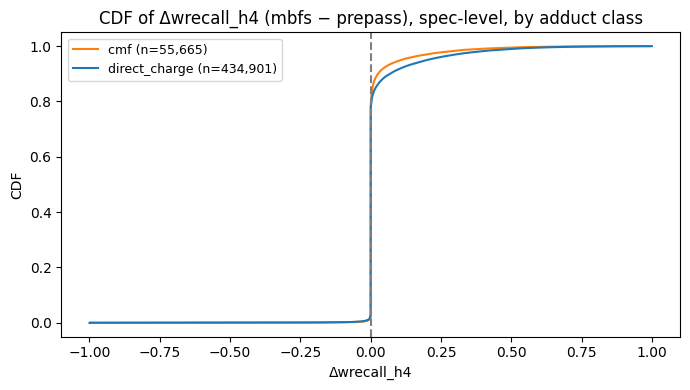

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
COLORS = {"direct_charge": "tab:blue", "cmf": "tab:orange", "other": "tab:gray"}
for cls, grp in spec_cmp.groupby("adduct_class"):
    vals = grp["wrecall_h4_delta"].sort_values()
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    ax.plot(vals, cdf, label=f"{cls} (n={len(vals):,})", color=COLORS.get(cls))
ax.axvline(0, color="gray", linestyle="--")
ax.set_title("CDF of Δwrecall_h4 (mbfs − prepass), spec-level, by adduct class")
ax.set_xlabel("Δwrecall_h4")
ax.set_ylabel("CDF")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Cross-reference: adduct mix of the top mol-level gainers

For the molecules with the biggest mol-level h4 wrecall gain, show which adduct class(es) their
spectra belong to — is the gain coming from CMF-adduct spectra, direct-charge spectra, or both?

In [11]:
top_mol_ids = top_improved.index
top_mol_adducts = (
    spec_cmp[spec_cmp["mol_id"].isin(top_mol_ids)]
    .groupby("mol_id")
    .agg(
        n_spectra=("adduct_class", "size"),
        adduct_classes=("adduct_class", lambda s: sorted(s.unique())),
        mean_spec_delta=("wrecall_h4_delta", "mean"),
    )
)
top_improved.join(top_mol_adducts)[
    ["smiles", "formula", "wrecall_h4_delta", "n_spectra", "adduct_classes", "mean_spec_delta"]
]

,smiles,formula,wrecall_h4_delta,n_spectra,adduct_classes,mean_spec_delta
mol_id,,,,,,
31493,O=C1CC2OCC=C3CN4CCC56c7ccccc7N1C5C2C3CC46,C21H22N2O2,0.759838,9,[direct_charge],0.715852
34119,Oc1c2ccccc2c2c3c(cccc13)N=N2,C14H8N2O,0.750847,8,[direct_charge],0.662295
15421,CN1CCC23CCCCC2C1Cc1ccc(O)cc13,C17H23NO,0.733593,19,[direct_charge],0.558760
34342,Oc1ccc2c(c1)C13CCCCC1C(C2)NCC3,C16H21NO,0.712032,10,[direct_charge],0.601343
20146,COc1ccc2c(c1)C13CCCCC1C(C2)N(C)CC3,C18H25NO,0.697574,10,[direct_charge],0.516858
6844,CC12Cc3nonc3CC1CCC1C2CCC2(C)C1CC(O)C2(C)O,C20H30N2O3,0.647316,11,[direct_charge],0.620504
18918,COc1cc2c(cc1OC)C13CCN4CC5=CCOC6CC(=O)N2C1C6C5CC43,C23H26N2O4,0.642984,8,[direct_charge],0.639663
1412,C=CCN1CCC23CCCCC2C1Cc1ccc(O)cc13,C19H25NO,0.602989,11,[direct_charge],0.524051
14540,CCOc1ccc2nc3cc([N+](=O)[O-])ccc3c(N)c2c1,C15H13N3O3,0.593377,2,[direct_charge],0.620008


## Which chemical classes need more SMARTS rules?

Join the per-molecule mbfs−prepass `wrecall_h4` gap with ClassyFire annotations
(`data/classyfire/nist20_mol_classyfire.pkl`). A class where mbfs *systematically* beats the
curated SMARTS prepass (high mean/median delta, not just a few outlier molecules) is a class
whose rearrangement chemistry isn't captured by any existing rule — a good candidate for a new
SMARTS rule. `sum_delta` additionally weights by class frequency to surface where the total
addressable gap is largest.

In [12]:
classyfire = pd.read_pickle("../../data/classyfire/nist20_mol_classyfire.pkl").set_index("mol_id")[
    ["superklass", "klass", "subklass"]
]

class_cmp = mol_cmp.join(classyfire, how="left")
print(f"Molecules missing classyfire annotation: {class_cmp['klass'].isna().sum():,} / {len(class_cmp):,}")


def summarize_by_class(df: pd.DataFrame, class_col: str, min_n: int = 20) -> pd.DataFrame:
    """Aggregate wrecall_h4_delta by chemical class, filtered to classes with enough molecules."""
    summary = df.groupby(class_col)["wrecall_h4_delta"].agg(
        n_mols="size",
        mean_delta="mean",
        median_delta="median",
        sum_delta="sum",
        frac_improved=lambda s: (s > 1e-6).mean(),
    )
    return summary[summary["n_mols"] >= min_n].sort_values("mean_delta", ascending=False)


klass_summary = summarize_by_class(class_cmp, "klass", min_n=20)
superklass_summary = summarize_by_class(class_cmp, "superklass", min_n=20)

Molecules missing classyfire annotation: 42 / 25,969


### `klass`-level ranking (min 20 molecules)

Sorted by `mean_delta` — the classes at the top are ones where mbfs consistently explains more
peaks than the SMARTS prepass across the whole class, not just isolated molecules.

In [13]:
klass_summary.head(25)

,n_mols,mean_delta,median_delta,sum_delta,frac_improved
klass,,,,,
morphinans,33,0.338204,0.313792,11.160745,1.000000
naphthofurans,27,0.148784,0.124353,4.017161,1.000000
phenanthrenes and derivatives,36,0.124354,0.126517,4.476758,0.861111
neoflavonoids,39,0.123422,0.117512,4.813471,1.000000
naphthopyrans,48,0.117273,0.115032,5.629106,1.000000
anthracenes,135,0.107105,0.098118,14.459137,0.918519
thienopyrimidines,51,0.103397,0.100538,5.273245,0.960784
benzodiazepines,70,0.087130,0.067382,6.099109,1.000000
isoflavonoids,225,0.082926,0.070694,18.658318,0.991111


### Same classes, ranked by aggregate opportunity (`sum_delta`)

Weights mean gap by class frequency — surfaces classes where a new rule would move the needle
most in absolute terms, even if the per-molecule gap isn't the single largest.

In [14]:
klass_summary.sort_values("sum_delta", ascending=False).head(25)

,n_mols,mean_delta,median_delta,sum_delta,frac_improved
klass,,,,,
steroids and steroid derivatives,749,0.076322,0.049102,57.165127,0.901202
prenol lipids,939,0.056393,0.016121,52.952793,0.686901
quinolines and derivatives,666,0.050868,0.026680,33.877769,0.921922
flavonoids,665,0.046169,0.038613,30.702244,0.975940
coumarins and derivatives,375,0.077226,0.064489,28.959564,0.904000
indoles and derivatives,880,0.029501,0.010116,25.960808,0.881818
isoflavonoids,225,0.082926,0.070694,18.658318,0.991111
benzopyrans,216,0.080752,0.064434,17.442396,0.962963
diazanaphthalenes,336,0.048356,0.034366,16.247780,0.907738


### `superklass`-level ranking (broader, more robust per-group counts)

In [15]:
superklass_summary

,n_mols,mean_delta,median_delta,sum_delta,frac_improved
superklass,,,,,
alkaloids and derivatives,227,0.150568,0.104180,34.179020,0.951542
"lignans, neolignans and related compounds",96,0.052082,0.032394,4.999851,0.625000
phenylpropanoids and polyketides,2114,0.044212,0.022305,93.464073,0.672185
lipids and lipid-like molecules,3018,0.036811,0.000000,111.094612,0.465871
organoheterocyclic compounds,8056,0.029849,0.000859,240.465118,0.537115
organic oxygen compounds,1110,0.012162,0.000000,13.499481,0.252252
"nucleosides, nucleotides, and analogues",163,0.009423,0.001318,1.536016,0.588957
organic acids and derivatives,2539,0.004590,0.000000,11.652879,0.141394
organosulfur compounds,176,0.004342,0.000000,0.764226,0.085227


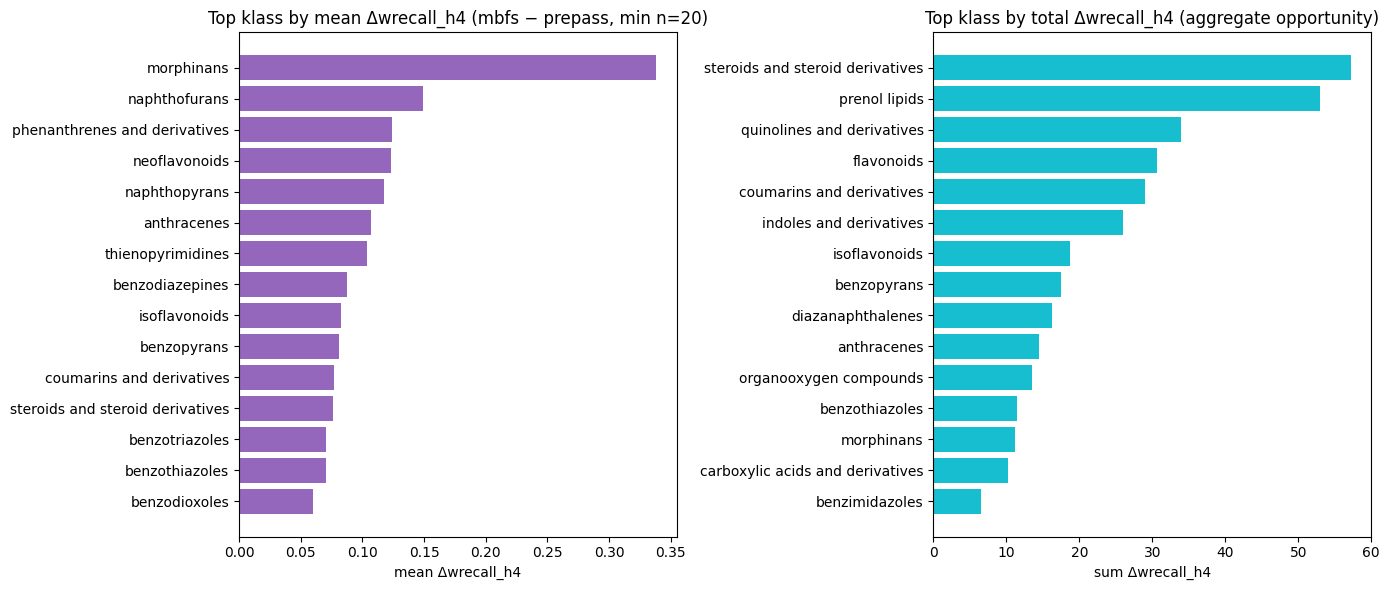

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

top_mean = klass_summary.head(15).iloc[::-1]
axes[0].barh(top_mean.index, top_mean["mean_delta"], color="tab:purple")
axes[0].set_title("Top klass by mean Δwrecall_h4 (mbfs − prepass, min n=20)")
axes[0].set_xlabel("mean Δwrecall_h4")

top_sum = klass_summary.sort_values("sum_delta", ascending=False).head(15).iloc[::-1]
axes[1].barh(top_sum.index, top_sum["sum_delta"], color="tab:cyan")
axes[1].set_title("Top klass by total Δwrecall_h4 (aggregate opportunity)")
axes[1].set_xlabel("sum Δwrecall_h4")

plt.tight_layout()
plt.show()

## Drilldown: steroids and steroid derivatives

`steroids and steroid derivatives` has the largest aggregate opportunity (`sum_delta`) and a high
`frac_improved` (90%), but the class mixes drug-like scaffolds (androgens, progestogens,
estrogens, corticosteroids) with natural-product-heavy subklasses (glycosides, bile acids,
cucurbitacins) that are less relevant if the goal is a rule for drug-like molecules. Break down
by `subklass` first, then pull a drug-like candidate list.

In [17]:
classyfire_full = pd.read_pickle("../../data/classyfire/nist20_mol_classyfire.pkl").set_index("mol_id")[
    ["klass", "subklass"]
]
steroid_cmp = mol_cmp.join(classyfire_full, how="left").join(mol_meta, how="left")
steroid_cmp = steroid_cmp[steroid_cmp["klass"] == "steroids and steroid derivatives"]

subklass_summary = steroid_cmp.groupby("subklass")["wrecall_h4_delta"].agg(
    n_mols="size",
    mean_delta="mean",
    median_delta="median",
    sum_delta="sum",
    frac_improved=lambda s: (s > 1e-6).mean(),
).sort_values("sum_delta", ascending=False)
subklass_summary

,n_mols,mean_delta,median_delta,sum_delta,frac_improved
subklass,,,,,
androstane steroids,80,0.122546,0.102145,9.803719,0.975000
pregnane steroids,105,0.085598,0.076757,8.987756,0.923810
hydroxysteroids,132,0.059388,0.029555,7.839201,0.848485
estrane steroids,53,0.128574,0.106403,6.814443,1.000000
oxosteroids,66,0.096009,0.066529,6.336621,0.924242
steroid lactones,80,0.070902,0.036764,5.672137,0.887500
steroid esters,54,0.061716,0.050004,3.332658,0.925926
steroidal glycosides,73,0.036966,0.013785,2.698490,0.863014
steroidal alkaloids,15,0.151982,0.178915,2.279731,1.000000


### Drug-like steroid candidate list

`androstane`, `pregnane`, `estrane`, `oxosteroids`, `steroid lactones`, `steroid esters` cover
the drug-relevant steroid scaffolds (anabolic steroids, progestins, estrogens, corticosteroids,
cardenolide/bufadienolide-type steroid lactones) — as opposed to `steroidal glycosides`,
`bile acids`, `cucurbitacins`, which are natural-product-heavy and less drug-like. These six
subklasses account for 438 of the 749 steroid molecules and most of the class's `sum_delta`.

In [18]:
DRUG_LIKE_STEROID_SUBKLASS = {
    "androstane steroids",
    "pregnane steroids",
    "estrane steroids",
    "oxosteroids",
    "steroid lactones",
    "steroid esters",
}

drug_like_steroids = (
    steroid_cmp[steroid_cmp["subklass"].isin(DRUG_LIKE_STEROID_SUBKLASS)]
    .sort_values("wrecall_h4_delta", ascending=False)
)
print(f"Drug-like steroid molecules: {len(drug_like_steroids):,}")
drug_like_steroids[["smiles", "formula", "mw", "subklass", f"{WCOL}_prepass", f"{WCOL}_mbfs", "wrecall_h4_delta"]].head(40)

Drug-like steroid molecules: 438


,smiles,formula,mw,subklass,wrecall_0.01_h4_prepass,wrecall_0.01_h4_mbfs,wrecall_h4_delta
mol_id,,,,,,,
6844,CC12Cc3nonc3CC1CCC1C2CCC2(C)C1CC(O)C2(C)O,C20H30N2O3,346.471,estrane steroids,0.272469,0.919785,0.647316
6472,CC1(C)OC2CC(=O)OCC23C1C(=O)C(=O)C1(C)C3CCC2(C)...,C26H28O9,484.501,oxosteroids,0.501831,0.948919,0.447089
6630,CC12CC(C=O)C(=O)CC1CCC1C2CCC2(C)C1CCC2(C)O,C21H32O3,332.484,androstane steroids,0.377862,0.805762,0.427899
6610,CC12C=CC(=O)CC1CCC1C2CCC2(C)C1CCC2(C)O,C20H30O2,302.458,androstane steroids,0.558698,0.985724,0.427026
181,C#CC1(O)CCC2C3CCC4=Cc5oncc5CC4(C)C3CCC21C,C22H27NO2,337.463,estrane steroids,0.494831,0.916037,0.421206
2466,CC(=O)OC1(C(C)=O)CCC2C3C=C(Cl)C4=CC(O)CCC4(C)C...,C23H31ClO4,406.950,pregnane steroids,0.121715,0.507968,0.386254
1804,CC(=O)C1CCC2(O)C3=C(CCC12C)C1(C)CC(O)C(O)CC1C(...,C21H30O5,362.466,androstane steroids,0.536331,0.915452,0.379122
6474,CC1(C)OC2CC(=O)OCC23C1CC(=O)C1(C)C3CCC2(C)C(c3...,C26H30O8,470.518,oxosteroids,0.439689,0.807900,0.368211
6839,CC12Cc3c([nH][nH]c3=O)CC1CCC1C2CCC2(C)C1CCC2(C)O,C21H32N2O2,344.499,estrane steroids,0.626426,0.989120,0.362694
